In [1]:
import math
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm

import torch
import torch.nn as nn

In [2]:
class NN(nn.Module):
    def __init__(self):
        super(NN, self).__init__()
        self.net = torch.nn.Sequential(
            nn.Linear(2,20),
            nn.Tanh(),
            nn.Linear(20,30),
            nn.Tanh(),
            nn.Linear(30,30),
            nn.Tanh(),
            nn.Linear(30,20),
            nn.Tanh(),
            nn.Linear(20,20),
            nn.Tanh(),
            nn.Linear(20,1)
        )

    def forward(self, x):
        out = self.net(x)
        return out  

In [3]:
class Net:
    def __init__(self):
        device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

        self.model = NN().to(device)
        # computation domain
        self.h = 0.1
        self.k = 0.1
        x = torch.arange(-1, 1+self.h, self.h)
        t = torch.arange(0, 1+self.k, self.k)

        self.X = torch.stack(torch.meshgrid(x,t)).reshape(2,-1).T

        # train data
        bc1 = torch.stack(torch.meshgrid(x[0],t)).reshape(2,-1).T
        bc2 = torch.stack(torch.meshgrid(x[-1],t)).reshape(2,-1).T
        ic = torch.stack(torch.meshgrid(x,t[0])).reshape(2,-1).T
        self.X_train = torch.cat([bc1, bc2, ic])

        y_bc1 = torch.zeros(len(bc1))
        y_bc2 = torch.zeros(len(bc2))
        y_ic = -torch.sin(math.pi * ic[:,0])
        self.y_train = torch.cat([y_bc1, y_bc2, y_ic])
        self.y_train = self.y_train.unsqueeze(1)

        self.X = self.X.to(device)
        self.y_train = self.y_train.to(device)
        self.X_train = self.X_train.to(device)
        self.X.requires_grad = True

        # optimizer setting
        self.adam = torch.optim.Adam(self.model.parameters())

        # tweaking adam optimizer for short memories (l-bfgs)
        self.optimizer = torch.optim.LBFGS(
            self.model.parameters(),
            lr=1.0,
            max_iter = 500000,
            max_eval = 500000,
            history_size = 50,
            tolerance_grad= 1e-7,
            tolerance_change=1.0 * np.finfo(float).eps,
            line_search_fn = "strong_wolfe"
        )

        self.criterion = torch.nn.MSELoss()
        self.iter = 1
        
    def loss_func(self):
        self.adam.zero_grad()
        self.optimizer.zero_grad()

        y_pred = self.model(self.X_train)
        loss_data = self.criterion(y_pred, self.y_train)

        u = self.model(self.X)

        du_dX = torch.autograd.grad(
            u,
            self.X,
            grad_outputs = torch.ones_like(u),
            create_graph = True,
            retain_graph = True
            )[0]

        # print(du_dX)
        # print("xxxxxxxxxxxxxxxxxxx")
        # print(du_dX[0])

        du_dt = du_dX[:,1]
        du_dx = du_dX[:,0]

        du_dXX = torch.autograd.grad(
            du_dX,
            self.X,
            grad_outputs = torch.ones_like(du_dX),
            create_graph = True,
            retain_graph = True
            )[0]

        du_dxx = du_dXX[:,0]

        loss_pde = self.criterion(du_dt + u.squeeze()*du_dx , (0.01/math.pi) * du_dxx)

        loss = loss_pde + loss_data
        loss.backward()

        if self.iter % 100 == 0:
            print(self.iter, loss.item())
        self.iter = self.iter + 1
        
        return loss

    def train(self):
        self.model.train()
        for i in range (1000):
            self.adam.step(self.loss_func)
        self.optimizer.step(self.loss_func)

    def eval_(self):
        self.model.eval()

In [4]:
# just for test
x_test = torch.arange(-1, 1+0.1, 0.1)
print(x_test)
t_test = torch.arange(0, 1+0.1, 0.1)
print(t_test)

X = torch.stack(torch.meshgrid(x_test,t_test)).reshape(2,-1).T

print(X)

# print(torch.meshgrid(x_test,t_test))


tensor([-1.0000e+00, -9.0000e-01, -8.0000e-01, -7.0000e-01, -6.0000e-01,
        -5.0000e-01, -4.0000e-01, -3.0000e-01, -2.0000e-01, -1.0000e-01,
        -2.9802e-09,  1.0000e-01,  2.0000e-01,  3.0000e-01,  4.0000e-01,
         5.0000e-01,  6.0000e-01,  7.0000e-01,  8.0000e-01,  9.0000e-01,
         1.0000e+00])
tensor([0.0000, 0.1000, 0.2000, 0.3000, 0.4000, 0.5000, 0.6000, 0.7000, 0.8000,
        0.9000, 1.0000])
tensor([[-1.0000e+00,  0.0000e+00],
        [-1.0000e+00,  1.0000e-01],
        [-1.0000e+00,  2.0000e-01],
        [-1.0000e+00,  3.0000e-01],
        [-1.0000e+00,  4.0000e-01],
        [-1.0000e+00,  5.0000e-01],
        [-1.0000e+00,  6.0000e-01],
        [-1.0000e+00,  7.0000e-01],
        [-1.0000e+00,  8.0000e-01],
        [-1.0000e+00,  9.0000e-01],
        [-1.0000e+00,  1.0000e+00],
        [-9.0000e-01,  0.0000e+00],
        [-9.0000e-01,  1.0000e-01],
        [-9.0000e-01,  2.0000e-01],
        [-9.0000e-01,  3.0000e-01],
        [-9.0000e-01,  4.0000e-01],
     

d:\PythonEnvs\tf_gpu\lib\site-packages\torch\functional.py:534: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\native\TensorShape.cpp:3596.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


In [5]:
# just for test
bc1_test = torch.stack(torch.meshgrid(x_test[0],t_test)).reshape(2,-1).T

print(bc1_test)

tensor([[-1.0000,  0.0000],
        [-1.0000,  0.1000],
        [-1.0000,  0.2000],
        [-1.0000,  0.3000],
        [-1.0000,  0.4000],
        [-1.0000,  0.5000],
        [-1.0000,  0.6000],
        [-1.0000,  0.7000],
        [-1.0000,  0.8000],
        [-1.0000,  0.9000],
        [-1.0000,  1.0000]])


In [6]:
# just for test
y_train_test = torch.tensor([1,2,3,4])
print(y_train_test)
y_train_test = y_train_test.unsqueeze(1)
print(y_train_test)

tensor([1, 2, 3, 4])
tensor([[1],
        [2],
        [3],
        [4]])


In [7]:
## training
net = Net()
net.train()

d:\PythonEnvs\tf_gpu\lib\site-packages\torch\autograd\graph.py:825: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\cuda\CublasHandlePool.cpp:135.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


100 0.19282373785972595
200 0.09482024610042572
300 0.08647650480270386
400 0.06991472840309143
500 0.0493723563849926
600 0.028305893763899803
700 0.01791895180940628
800 0.025859542191028595
900 0.013687320053577423
1000 0.011896470561623573
1100 0.007794219069182873
1200 0.00474248081445694
1300 0.00310220243409276
1400 0.0020425233524292707
1500 0.0015600897604599595
1600 0.0015235742321237922
1700 0.0010157828219234943
1800 0.0007397885201498866
1900 0.000617408542893827
2000 0.0005020721582695842
2100 0.00039807037683203816
2200 0.00032193062361329794
2300 0.0002612101088743657
2400 0.0002276028972119093
2500 0.00020992563804611564
2600 0.0001662647700868547
2700 0.00014307866513263434
2800 0.00012553873239085078
2900 0.00011342509969836101
3000 0.00010222932905890048
3100 9.262964886147529e-05
3200 8.43071611598134e-05
3300 7.655523222638294e-05
3400 6.94111586199142e-05
3500 6.396326352842152e-05
3600 5.7459299569018185e-05
3700 5.188098657527007e-05
3800 4.896132668363862e-05


In [8]:
net.model.eval()

NN(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=20, bias=True)
    (1): Tanh()
    (2): Linear(in_features=20, out_features=30, bias=True)
    (3): Tanh()
    (4): Linear(in_features=30, out_features=30, bias=True)
    (5): Tanh()
    (6): Linear(in_features=30, out_features=20, bias=True)
    (7): Tanh()
    (8): Linear(in_features=20, out_features=20, bias=True)
    (9): Tanh()
    (10): Linear(in_features=20, out_features=1, bias=True)
  )
)

In [9]:
h = 0.01
k = 0.01

x = torch.arange(-1,1,h)
t = torch.arange(0,1,k)

X = torch.stack(torch.meshgrid(x,t)).reshape(2,-1).T
X = X.to(net.X.device)

In [10]:
X

tensor([[-1.0000,  0.0000],
        [-1.0000,  0.0100],
        [-1.0000,  0.0200],
        ...,
        [ 0.9900,  0.9700],
        [ 0.9900,  0.9800],
        [ 0.9900,  0.9900]], device='cuda:0')

In [11]:
X.shape

torch.Size([20000, 2])

In [12]:
model = net.model
model.eval()
with torch.no_grad():
    y_pred = model(X)
    y_pred = y_pred.reshape(len(x),len(t)).cpu().numpy()

In [13]:
y_pred

array([[ 0.00215718,  0.00179228,  0.0015029 , ..., -0.00132537,
        -0.0013237 , -0.00132063],
       [ 0.03400782,  0.03266427,  0.03145418, ...,  0.00629264,
         0.00623611,  0.00618172],
       [ 0.06567553,  0.06336644,  0.06124744, ...,  0.01391456,
         0.01379985,  0.01368839],
       ...,
       [-0.09381941, -0.09113154, -0.08861327, ..., -0.02491885,
        -0.02475822, -0.02460328],
       [-0.0618912 , -0.0601801 , -0.05858585, ..., -0.01710486,
        -0.01700661, -0.01691243],
       [-0.02975053, -0.02903715, -0.02838543, ..., -0.0092904 ,
        -0.00925407, -0.00922081]], shape=(200, 100), dtype=float32)

In [14]:
y_pred.shape

(200, 100)

In [15]:
sns.set_style("white")
plt.figure(figsize=(5,3), dpi=3000)
sns.heatmap(y_pred, cmap='jet')

<Axes: >

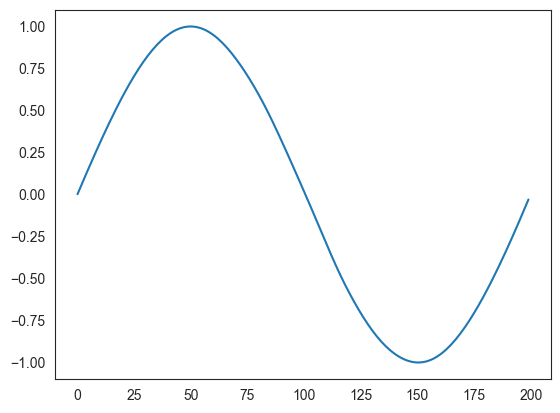

In [16]:
plt.plot(y_pred[:,0])

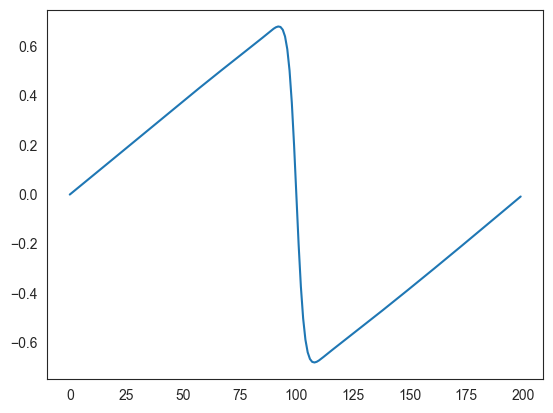

In [17]:
plt.plot(y_pred[:,-1])

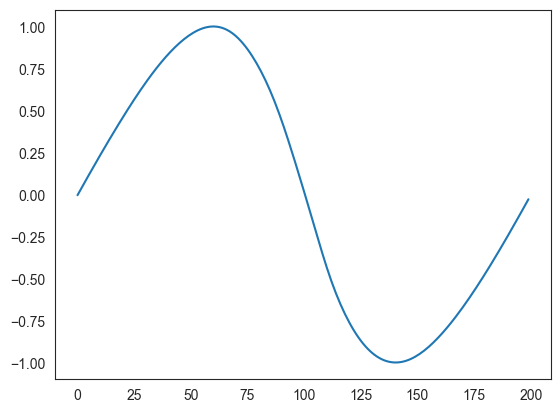

In [21]:
plt.plot(y_pred[:,10])

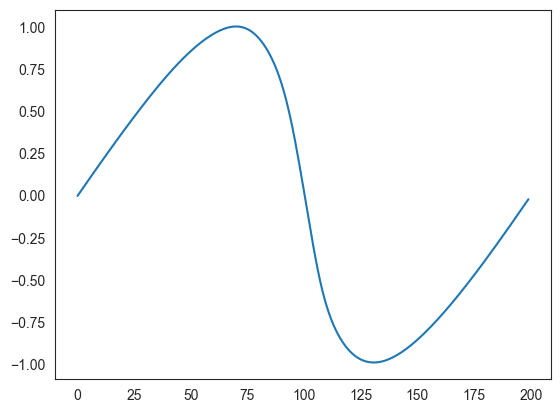

In [22]:
plt.plot(y_pred[:,20])

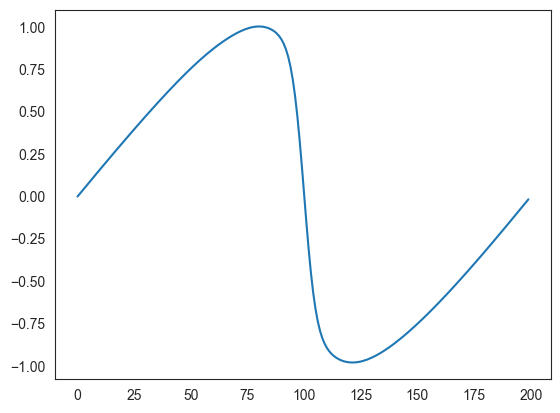

In [23]:
plt.plot(y_pred[:,30])

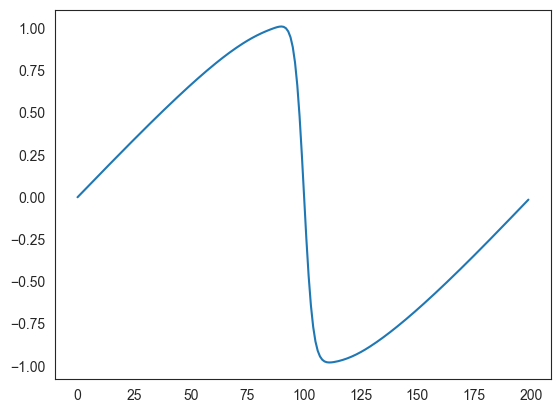

In [24]:
plt.plot(y_pred[:,40])